In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hw5.ipynb")

# CPSC 330 - Applied Machine Learning 

## Homework 5: Credit default classification 
### Associated lectures: All material till Chapter 13 

## Table of contents
0. [Submission instructions](#si)
1. [Understanding the problem](#1)
2. [Data splitting](#2)
3. [EDA](#3)
4. (Challenging) [Feature engineering](#4)
5. [Preprocessing and transformations](#5) 
6. [Baseline model](#6)
7. [Linear models](#7)
8. [Different models](#8)
9. (Challenging) [Feature selection](#9)
10. [Hyperparameter optimization](#10)
11. [Interpretation and feature importances](#11) 
12. [Results on the test set](#12)
13. [Summary of the results](#13)
14. (Challenging) [Your takeaway from the course](#15)

<div class="alert alert-info">

## Instructions
rubric={points}

You will earn points for following these instructions and successfully submitting your work in PrairieLearn.

### Group work instructions

**You may work with a partner on this homework and submit your assignment as a group.** Below are some instructions on working as a group.

- The maximum group size is 2.
- Use group work as an opportunity to collaborate and learn new things from each other.
- Be respectful to each other and make sure you understand all the concepts in the assignment well.
- It is your responsibility to make sure your PrairieLearn group is set up correctly and that the assignment is submitted before the deadline.

### General submission instructions

- Please read the [Use of Generative AI policy](https://ubc-cs.github.io/cpsc330-2026W1/syllabus/#use-of-generative-ai-genai) before starting the homework assignment.
- **Run all cells before submitting:** Go to `Kernel -> Restart Kernel and Clear All Outputs`, then select `Run -> Run All Cells`. This ensures your notebook runs cleanly from start to finish without errors.
- **Save your work in JupyterLab:** Make sure `hw5.ipynb` is saved.
- **Choose one HW5 option:** HW5 has two dataset options in PrairieLearn. You are currently in the credit default classification option. Open and submit exactly one notebook, and do not submit both.
- **Check your saved submission in PrairieLearn:** Return to the PrairieLearn question page and click **Save only** to capture your notebook and review the preview. When you are ready to submit for grading, click **Save & Grade**.
- **Follow course submission guidelines:** Review the CPSC 330 homework instructions for detailed guidance on completing and submitting assignments.

</div>


# 14 Final report

Final test score: average precision = 0.573 (tuned LightGBM). Average precision was chosen here because the classes are imbalanced(22% default). 

## Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

<!-- BEGIN QUESTION -->



In [3]:
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, RandomizedSearchCV

from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.dummy import DummyClassifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

from sklearn.feature_selection import RFECV 

from scipy.stats import loguniform, randint, uniform 
import shap

from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, confusion_matrix

<!-- END QUESTION -->

## Introduction <a name="in"></a>

In this homework you will be working on an open-ended mini-project, where you will put all the different things you have learned so far together to solve an interesting problem.

A few notes and tips when you work on this mini-project: 

#### Tips
1. This mini-project is open-ended, and while working on it, there might be some situations where you'll have to use your own judgment and make your own decisions (as you would be doing when you work as a data scientist). Make sure you explain your decisions whenever necessary. 
2. **Do not include everything you ever tried in your submission** -- it's fine just to have your final code. That said, your code should be reproducible and well-documented. For example, if you chose your hyperparameters based on some hyperparameter optimization experiment, you should leave in the code for that experiment so that someone else could re-run it and obtain the same hyperparameters, rather than mysteriously just setting the hyperparameters to some (carefully chosen) values in your code. 
3. If you realize that you are repeating a lot of code try to organize it in functions. Clear presentation of your code, experiments, and results is the key to be successful in this lab. You may use code from lecture notes or previous lab solutions with appropriate attributions. 

#### Assessment
We plan to grade fairly and leniently. We don't have some secret target score that you need to achieve to get a good grade. **You'll be assessed on demonstration of mastery of course topics, clear presentation, and the quality of your analysis and results.** For example, if you just have a bunch of code and no text or figures, that's not good. If you do a bunch of sane things and get a lower accuracy than your friend, don't sweat it.


#### A final note
Finally, this style of this "project" question is different from other assignments. It'll be up to you to decide when you're "done" -- in fact, this is one of the hardest parts of real projects. But please don't spend WAY too much time on this... perhaps "a few hours" (15-20 hours???) is a good guideline for this project . Of course if you're having fun you're welcome to spend as much time as you want! But, if so, try not to do it out of perfectionism or getting the best possible grade. Do it because you're learning and enjoying it. Students from the past cohorts have found such kind of labs useful and fun and we hope you enjoy it as well. 

<br><br>

<!-- BEGIN QUESTION -->

<!-- BEGIN QUESTION -->

## 1. Pick your problem and explain the prediction problem
<hr>
rubric={points:3}

This version of Homework 5 uses the [Default of Credit Card Clients Dataset](https://www.kaggle.com/uciml/default-of-credit-card-clients-dataset). You will work on a classification problem where the goal is to predict whether a credit card client will default on their payment next month. In this dataset, there are 30,000 examples and 24 features, and the target column is labeled `default.payment.next.month`. The remaining columns can be used as features. You may take some ideas and compare your results with [the associated research paper](https://www.sciencedirect.com/science/article/pii/S0957417407006719), which is available through [the UBC library](https://www.library.ubc.ca/).

<div class="alert alert-info">
    
**Your tasks:**

1. Spend some time understanding the problem and what each feature means. Use the Kaggle documentation to guide you.
2. Download the dataset and load it into a pandas DataFrame.
3. Write a few sentences summarizing your initial thoughts about the problem and the dataset.
   
</div>


<div class="alert alert-warning">
    
Solution_1
    
</div>

_Points:_ 3

#### The problem

Binary classification. Predict whether a client will defualt next month, using 23 features for 30,000 clients. 

We have class imbalance, around 22% defualt and 78% dont. So accuracy would be misleading. We will need to use a metric like F1, recall or AP. 

The repayment history PAY_* probably predicts defualt best, since recent late payments are a strong signal, while something like ID is useless. 

BILL_AMT1... BILL_AMT6 are probably highly correlated with each other, and the same goes for the PAY_* columns. That might matter for a linear model. 

The data is from one Taiwan bank in 2005, so we may not generalize to other populations well. Sensitive features like SEX and AGE and MARRIAGE also raise fairness questions if we decide to use them for credit decisions. 

| Column | Meaning | 
|--------|---------|
| ID | ID of each client, not a feature. We should be dropping this. |
| LIMIT_BAL | Credit limit in NT dollars |
| SEX | Gender, 1 = male, 2 = female |
| EDUCATION | 1 = Graduate school, 2 = University, 3 = High school, 4 = Other 5,6 are unknown|
| MARRIAGE | Marital status where 1 = Married, 2 = Single, 3 = Others | 
| AGE | Age in years |
| PAY_0, PAY_2... PAY_6| Repayment Status for Sept 2005 back to April 2005. (-1) = Paid Duly, 1 = Payment Delay for a month, 2 = Payment Delay for two months, .. 8 = Payment Delay for eight months, 9 = Payment Delay for 9 months or above|
| BILL_AMT1... BILL_AMT6 | Amount of bill statements in Sept 2005 back to April 2005 in NT dollars |
| PAY_AMT1... PAY_AMT6 | Amount of previous payment in Sept 2005 back to April 2005, in NT dollars |
| default.payment.next.month | Default Payment 1 = yes, 0 = no |

Some things dont match the description. 
1. There is no PAY_1, instead it is labeled PAY_0. We pair this with BILL_AMT1 and PAY_AMT1 
2. There are afew undocumented values, meainly EDUCATION containing 0, MARRIAGE contains 0. The PAY_* column contains -2 and 0, which the paper's scale doesn't really define. People commonly read them as "no consumption" and "revolving credit, paid the minimum", but the paper itself doesnt confirm that 
3. Negative bills. BILL_AMT has negative values, which probably just means that the consumer overpaid and now has a credit balance
4. The paper's samples are not the same as mine. it uses 25,000 observations, while i have 30,000. The defualt rate is similar, around 22%, matching the paper's 22.12%

In [4]:
df = pd.read_csv("data/UCI_Credit_Card.csv")
df.shape
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 2. Data splitting <a name="2"></a>
<hr>
rubric={points:2}

**Your tasks:**

1. Split the data into train (70%) and test (30%) portions with `random_state=123`.

> If your computer cannot handle training on 70% training data, make the test split bigger.  

<div class="alert alert-warning">
    
Solution_2
    
</div>

_Points:_ 2

In [5]:
train_df, test_df = train_test_split(df, test_size=0.3, random_state=123, stratify=df["default.payment.next.month"])
X_train = train_df.drop(columns=["default.payment.next.month"])
y_train = train_df["default.payment.next.month"] 
X_test = test_df.drop(columns=["default.payment.next.month"])
y_test = test_df["default.payment.next.month"]

X_train.head()
y_train.head()
X_test.head()
y_test.head()

print(df["default.payment.next.month"].mean())
print(y_train.mean())
print(y_test.mean())

0.2212
0.2211904761904762
0.2212222222222222


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 3. EDA <a name="3"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Perform exploratory data analysis on the train set.
2. Include at least two summary statistics and two visualizations that you find useful, and accompany each one with a sentence explaining it.
3. Summarize your initial observations about the data. 
4. Pick appropriate metric/metrics for assessment. 

<div class="alert alert-warning">
    
Solution_3
    
</div>

_Points:_ 10

Summary Statistic One! 

Here we see each row of the output gives the defualt rate and the number of clients for one PAY_0 value. 

Clients with PAY_0 of -2, -1 or 0 defualt to about 13% to 17% of the time. 
PAY_0=1 jumps to about 34% and PAY_0=2 to about 68%. 
Beyond 2, the count are tiny, so those rates are mostly all noise

this supports the earlier hypothesis that a repayment histroy is the strongest signal

In [6]:
target = "default.payment.next.month"
train_df.groupby("PAY_0")[target].agg(["mean", "count"])

,mean,count
PAY_0,,
-2,0.133745,1944
-1,0.168135,3973
0,0.128720,10317
1,0.342034,2567
2,0.683761,1872
3,0.737991,229
4,0.722222,54
5,0.470588,17
6,0.571429,7


Summary Statistic Two! 

Defualt rate by credit limit quartile

Here the defualt rate falls steadily as the limit rises, about 31.5% in the lowest quartile down to about 14% in the highest. Higher limits go to clients the bank trusts more. 

In [7]:
train_df.groupby(pd.qcut(train_df["LIMIT_BAL"], 4))[target].mean()

LIMIT_BAL
(9999.999, 50000.0]      0.315258
(50000.0, 140000.0]      0.247796
(140000.0, 240000.0]     0.173264
(240000.0, 1000000.0]    0.143001
Name: default.payment.next.month, dtype: float64

Visualization 1, class balance

The bar shows us that about 78% vs 22%, the imbalance. 

Text(0, 0.5, 'proportion')

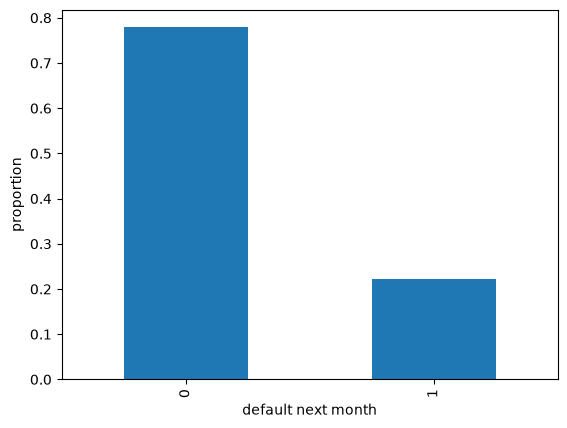

In [8]:
train_df[target].value_counts(normalize=True).plot.bar()
plt.xlabel("default next month"); plt.ylabel("proportion")

Visualization 2: Correlation heatmap of the bill amounts

The idea in second 1 is correct, where the six bill amounts are highly correlated with eachother(about 0.80 to 0.95), and neighbouring months are the most correlated. That matters for linear models and suggests feature engineering, such as averages or differences between months. 

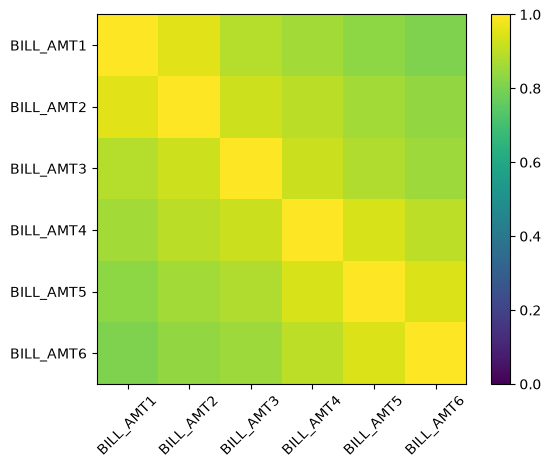

In [9]:
bills = [f"BILL_AMT{i}" for i in range(1, 7)]
plt.imshow(train_df[bills].corr(), vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(6), bills, rotation=45); plt.yticks(range(6), bills);

Other details: 

SEX has a small effect(male 24.2% vs female 20.7% default rate), and AGE is closer to uncorrelated with default. 

The linear correlation of PAY_0 with the target is the highest(around 0.32), and the bill amounts are near 0, so the bills alone dont tell us much

The oddly coded EDUCATION values of 0, 5, 6 have very very small counts

Additional Graphs below considered

Text(0, 0.5, 'default rate')

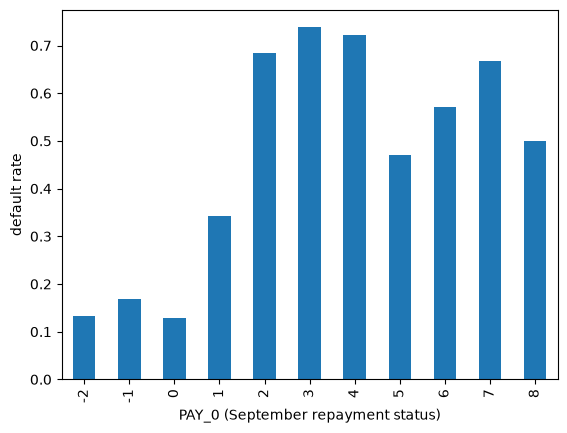

In [10]:
train_df.groupby("PAY_0")[target].mean().plot.bar()
plt.xlabel("PAY_0 (September repayment status)"); plt.ylabel("default rate")

Text(0, 0.5, 'default rate')

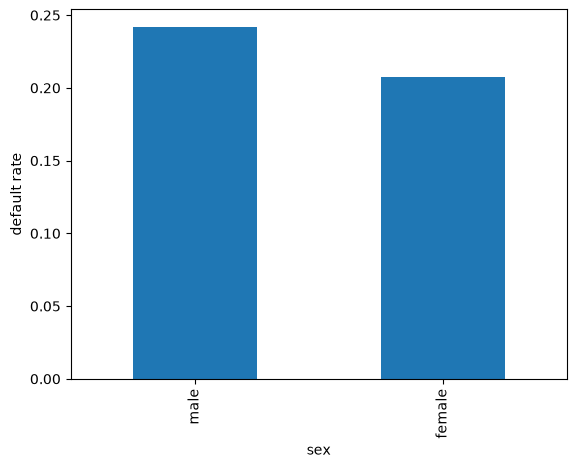

In [11]:
train_df.groupby("SEX")[target].mean().rename({1: "male", 2: "female"}).plot.bar()
plt.xlabel("sex"); plt.ylabel("default rate")

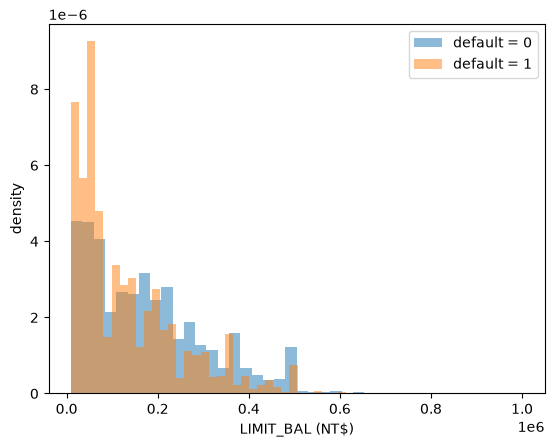

In [12]:
for label, group in train_df.groupby(target):
    plt.hist(group["LIMIT_BAL"], bins=40, alpha=0.5, density=True, label=f"default = {label}")
plt.xlabel("LIMIT_BAL (NT$)"); plt.ylabel("density"); plt.legend();

Text(0, 0.5, 'default rate')

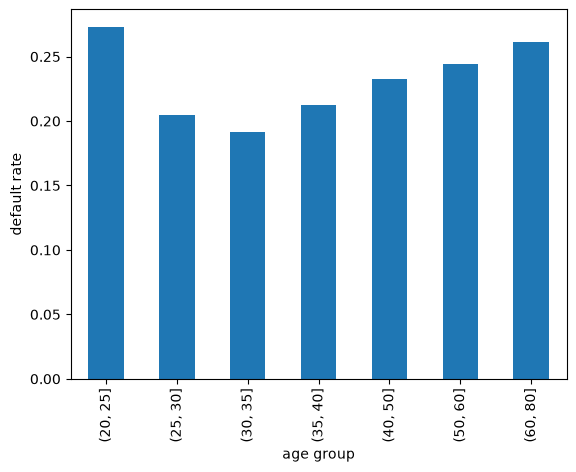

In [13]:
train_df.groupby(pd.cut(train_df["AGE"], [20, 25, 30, 35, 40, 50, 60, 80]))[target].mean().plot.bar()
plt.xlabel("age group"); plt.ylabel("default rate")

Text(0.5, 0, 'correlation with default')

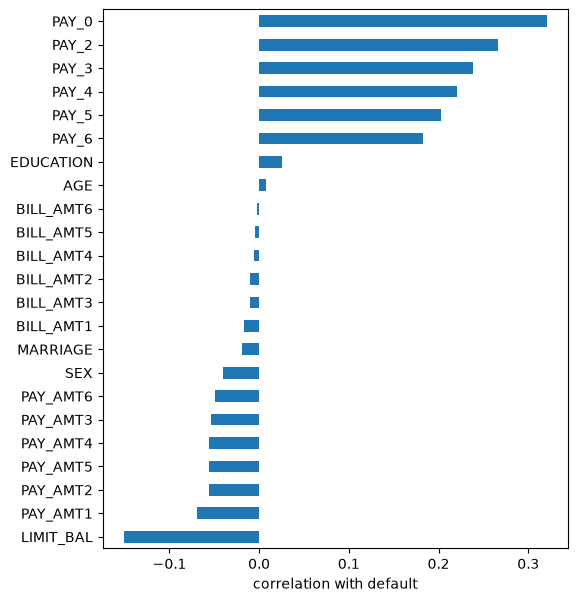

In [14]:
correlation = train_df.drop(columns="ID").corr()[target].drop(target).sort_values()
correlation.plot.barh(figsize=(6, 7))
plt.xlabel("correlation with default")

Text(0, 0.5, 'default rate')

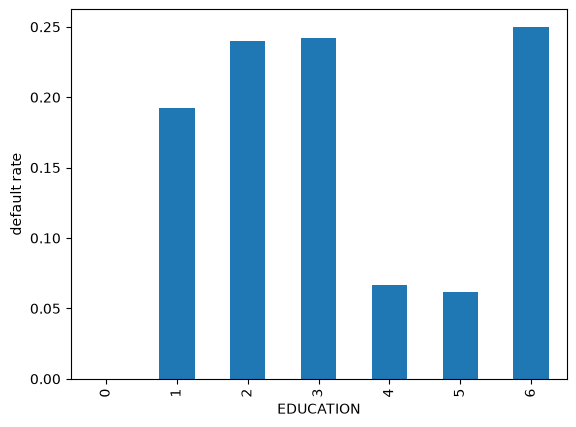

In [15]:
train_df.groupby("EDUCATION")[target].mean().plot.bar()
plt.xlabel("EDUCATION")
plt.ylabel("default rate")

The metric! 

Accuracy is a poor choice here because of the 78/22 split. Reasonable options would be either the F1 on the default class, recall, or using average precision.

Thinking of the costs: 
Missing a defaulter(false negative) usually costs the bank more than flagging a good customer(false positive), which argues for caring about the recall, but pure recall can be gamed by predicting the default for everyone. F1 balances precision and recall at one threshold, and average precision summarizes performance across all of these thresholds. 

I will choose to use AP as the primary metric with a small report on F1 on the side as a secondary metric. 

I choose AP for two
- it doesnt give me a decision. AP directly relates how well the model ranks clients by risk. To actually flag defaulters we will need to pick a threhsold, and AP says absolutely nothing about where we should have this threshold. This is why we are still reporting F1 as a secondary since it shows how the model does at a concrete cutoff 
- it ignores the costs of mistakes. if missing a defaulter costs the bank much more than a false alarm, AP wont reflect that. It weights all thresholds, including ones that I wouldnt use

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 4. Feature engineering <a name="4"></a>
<hr>
rubric={points:1}

**Your tasks:**

1. Carry out feature engineering. In other words, extract new features relevant for the problem and work with your new feature set in the following exercises. You may have to go back and forth between feature engineering and preprocessing. 

<div class="alert alert-warning">
    
Solution_4
    
</div>

_Points:_ 1

In [16]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

def add_features(d):
    d = d.copy()
    d["months_late"] = (d[pay_cols] > 0).sum(axis=1)        # how many of the 6 months were late
    d["max_delay"] = d[pay_cols].max(axis=1)                # worst delay
    d["util_recent"] = d["BILL_AMT1"] / d["LIMIT_BAL"]      # credit utilization last month
    d["avg_payment"] = d[pay_amt_cols].mean(axis=1)         # typical amount paid
    return d

train_df = add_features(train_df)
test_df = add_features(test_df)

X_train = train_df.drop(columns=[target])
y_train = train_df[target]
X_test = test_df.drop(columns=[target])
y_train = test_df[target]

print(X_train.shape, X_test.shape)   # shoulld be (21000, 28) (9000, 28)
X_train[["months_late", "max_delay", "util_recent", "avg_payment"]].head()

(21000, 28) (9000, 28)


,months_late,max_delay,util_recent,avg_payment
14451,0,-1,0.145600,650.000000
18392,0,0,0.000696,2430.500000
24955,2,2,0.000000,694.666667
7162,1,2,0.999411,3850.000000
12125,3,2,0.317250,420.666667


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 5. Preprocessing and transformations <a name="5"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Identify any data cleaning that needs to be done and perform it.
2. Identify different feature types and the transformations you would apply on each feature type. 
3. Define a column transformer, if necessary.
4. You have likely noticed the `number_of_reviews` of reviews feature will be higly informative for the target `reviews_per_month`. To make this assignment more interesting **drop** the `number_of_reviews` feature.

<div class="alert alert-warning">
    
Solution_5
    
</div>

_Points:_ 10

#### Cleaning

We start off with some data cleaning. So we have to drop out our ID column, make sure that y train,test are both only looking at the target, and then clean out the education and marriage columns by replacing their undocumented values with documented values. These mappings are all row wise with nothing else being fit, so applying them to the train and test sets is safe. We also manipulate the bills columns abit, by converting into a log scale since the current range of values is very very large. we use log to fix the shape, and then we scale to put it on the same scale as the other features(scaling is done in the column transform section).

In [17]:
amount_features = ["LIMIT_BAL"] + bill_cols + pay_amt_cols + ["avg_payment"] # all NT$ amounts

def clean(d): 
    d = d.copy(); 
    d["EDUCATION"] = d["EDUCATION"].replace({0: 4, 5: 4, 6: 4}) # undocumented, 5/6 is unknown -> merge into "others"
    d["MARRIAGE"] = d["MARRIAGE"].replace({0:3}) # similar problem, 0 undocumented, merge into "others"

    for col in amount_features:
        d[col] = np.sign(d[col]) * np.log1p(np.abs(d[col])) #we keep the sign and log(1 + x) scale to prevent log(0) = inf errors

    return d 

train_df = clean(train_df)
test_df = clean(test_df)

X_train = train_df.drop(columns=[target, "ID"]) # ID is an identifyer not a predictive feature 
y_train = train_df[target]

X_test = test_df.drop(columns=[target, "ID"])
y_test = test_df[target]

print(X_train.head() )
print(y_train.head()) 

print(X_test.head() )
print(y_test.head())

       LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
14451   9.903538    1          3         1   52     -1     -1     -1     -1   
18392  12.345839    2          2         2   24     -1     -1     -1     -1   
24955  12.793862    1          3         2   31      1     -1      2     -1   
7162   11.407576    2          2         1   26      2      0      0      0   
12125   9.903538    2          1         2   29      1      2      0      0   

       PAY_5  ...  PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  PAY_AMT6  \
14451     -1  ...  5.968708  6.660575  6.660575  6.660575  5.968708  6.660575   
18392     -1  ...  5.472271  6.375025  9.434443  7.130899  0.000000  0.000000   
24955      0  ...  5.476464  0.000000  8.224432  5.303305  0.000000  0.000000   
7162       0  ...  8.517393  8.366603  8.160804  8.160804  8.216358  8.039480   
12125      0  ...  0.000000  7.020191  6.023448  6.543912  0.000000  5.707110   

       months_late  max_delay  util_re

#### Feature groups and column transformer

now we move onto feature types and transformations, and then we will run a quick column transformer wrapping all of the preprocessing together. I have included the package imports in the allocated slot above question 1. 

Explaining amount_features abit more: theyre all money amounts in NT dollars with afew very large values, which is what the log fixes. avg_payment is build from PAY_AMT, so it has the same tails. To be abit more precise, LIMIT_BAL is only mildly skewed(about 1.0 compared to 15 for PAY_AMT), so the log matters less for it. it's included to treat all money columns consistently, and the log doesnt hurt it that much. util_recent isnt included because its a ratio, not an amount, and its rage is already pretty small. 

features are self explanatory below, abit more justification is written in where needed in the column transformer. 

In [18]:
numeric_features = amount_features + ["AGE", "months_late", "max_delay", "util_recent"]
pay_status_features = pay_cols # default risk jumps pretty sharply at 1-2 months late, so its not linear, therefore we onehot it. 
binary_features = ["SEX"]
categorical_features = ["EDUCATION", "MARRIAGE"] # unordered categories

preprocessor = make_column_transformer(
    # we scale so features with large ranges dont dominate. matters for KNN, SVM, linear models. 
    (StandardScaler(), numeric_features), 
    # ignore: rare pay levles may be missing from a CV training fold but appear in its validation folds 
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), pay_status_features), 
    # one 0/1 column; both values always present in training, so no unknown handles
    (OneHotEncoder(drop="if_binary", dtype=int), binary_features),
    # ignore: safety net for categories unseen during the fit
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
)

preprocessor.fit_transform(X_train).shape #should come out to 21000 89

(21000, 89)

Showing the preprocessor works: 

In [19]:
X_train_enc = preprocessor.fit_transform(X_train)
print(X_train_enc.shape)
preprocessor.get_feature_names_out()[:15]

(21000, 89)


array(['standardscaler__LIMIT_BAL', 'standardscaler__BILL_AMT1',
       'standardscaler__BILL_AMT2', 'standardscaler__BILL_AMT3',
       'standardscaler__BILL_AMT4', 'standardscaler__BILL_AMT5',
       'standardscaler__BILL_AMT6', 'standardscaler__PAY_AMT1',
       'standardscaler__PAY_AMT2', 'standardscaler__PAY_AMT3',
       'standardscaler__PAY_AMT4', 'standardscaler__PAY_AMT5',
       'standardscaler__PAY_AMT6', 'standardscaler__avg_payment',
       'standardscaler__AGE'], dtype=object)

Experiment for thhe PAY_* decision above: 

In [20]:
# same preprocessor as above execpt here pay_status_features is a numeric value
preprocessor_pay_numeric = make_column_transformer(
    (StandardScaler(), numeric_features + pay_status_features),
    (OneHotEncoder(drop="if_binary", dtype=int), binary_features),
    (OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
)

# here we just match the above preprocessor with the numeric version and we can see a slightly better AP
for name, pre in [("PAY_* numeric", preprocessor_pay_numeric), ("PAY_* one-hot", preprocessor)]:
    pipe = make_pipeline(pre, LogisticRegression(max_iter=3000))
    scores = cross_validate(pipe, X_train, y_train, scoring="average_precision")
    print(f"{name}: AP = {scores['test_score'].mean():.3f} \u00B1 {scores['test_score'].std():.3f}")

PAY_* numeric: AP = 0.510 ± 0.016
PAY_* one-hot: AP = 0.541 ± 0.013


Item 4 is not applicable here, must be for the other data set option. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 6. Baseline model <a name="6"></a>
<hr>
rubric={points:2}

**Your tasks:**
1. Try `scikit-learn`'s baseline model and report results.

<div class="alert alert-warning">
    
Solution_6
    
</div>

_Points:_ 2

Here we see that the dummy ignores the features entirely, and it just always predicts the majority class(no defaults), and its predict_proba is always returning the class proportion. 

A key takeaway here is that the accuracy of this model is 0.779 but it is entirely useless. We are just clicking the majority here without a second thought.

F1 here is 0 becuase it never predicts a default value, so recall and precision for the default class are both 0. 

AP is 0.221, equal to the default rate from before. A model with no ability to rank clients by the risk model gets an AP equal to the fraction of the positive values. This is the number that we are trying to beat or outperform 

Train and validation scores are identical here with 0 spread, which makes sense for a model that learns nothing, and since we set the classes to be proportional in the beginning. 

In [21]:
scoring = ["average_precision", "f1", "accuracy"]
results = {}

def cv_summary(model, X, y, scoring=scoring, n_jobs=-1): 
    """Run 5-fold CV and return the mean \u00B1 std for each metric"""
    scores = pd.DataFrame(cross_validate(model, X, y, scoring=scoring, return_train_score=True, n_jobs=n_jobs))
    return scores.agg(["mean", "std"]).T.round(3)

results["dummy"] = cv_summary(DummyClassifier(), X_train, y_train)
results["dummy"]

,mean,std
fit_time,0.008,0.000
score_time,0.011,0.001
test_average_precision,0.221,0.000
train_average_precision,0.221,0.000
test_f1,0.000,0.000
train_f1,0.000,0.000
test_accuracy,0.779,0.000
train_accuracy,0.779,0.000


<!-- END QUESTION -->



<!-- BEGIN QUESTION -->

## 7. Linear models <a name="7"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Try a linear model as a first real attempt. 
2. Carry out hyperparameter tuning to explore different values for the complexity hyperparameter. 
3. Report cross-validation scores along with standard deviation. 
4. Summarize your results.

<div class="alert alert-warning">
    
Solution_7
    
</div>

_Points:_ 10

Here we use a linear model as a first real attempt. 

We start by making a pipeline with the preprocessor and the logistic regressor. then we throw together a param grid for C on a log scale, and the class weight setting. I choose to show the class weight setting on NONE and BALANCED because this will show us the descripancy between AP and F1 in abit. 

once we get the results and display the results together in a linear plot, we get the following. 

In [22]:
pipe_lr = make_pipeline(preprocessor, LogisticRegression(max_iter=5000, random_state=123))

param_grid = {
    "logisticregression__C": 10.0 ** np.arange(-4,4), # goes from 0.0001 to 1000 log spaced
    "logisticregression__class_weight": [None, "balanced"],
}

grid_lr = GridSearchCV(
    pipe_lr, param_grid, 
    scoring=["average_precision", "f1"],
    refit="average_precision", 
    return_train_score=True, 
    n_jobs=-1,
)

grid_lr.fit(X_train, y_train)
print(grid_lr.best_params_, grid_lr.best_score_)

{'logisticregression__C': np.float64(0.1), 'logisticregression__class_weight': None} 0.5419485925438654


In [23]:
lr_results = pd.DataFrame(grid_lr.cv_results_)[[
    "param_logisticregression__C", "param_logisticregression__class_weight",
    "mean_train_average_precision", "mean_test_average_precision", "std_test_average_precision",
    "mean_test_f1", "std_test_f1", "mean_fit_time",
]]
lr_results

,param_logisticregression__C,param_logisticregression__class_weight,mean_train_average_precision,mean_test_average_precision,std_test_average_precision,mean_test_f1,std_test_f1,mean_fit_time
0,0.0001,NaN,0.498839,0.498890,0.014581,0.062208,0.006097,0.176628
1,0.0001,balanced,0.498689,0.498731,0.014678,0.517478,0.012055,0.176695
2,0.0010,NaN,0.518139,0.516682,0.013898,0.363963,0.020739,0.229840
3,0.0010,balanced,0.517687,0.516299,0.013763,0.529842,0.013099,0.169834
4,0.0100,NaN,0.541411,0.536913,0.012192,0.436814,0.021424,0.312835
5,0.0100,balanced,0.538102,0.534455,0.011975,0.535318,0.013158,0.220077
6,0.1000,NaN,0.550516,0.541949,0.013624,0.458406,0.014499,0.632188
7,0.1000,balanced,0.545976,0.539858,0.013209,0.536989,0.012179,0.453679
8,1.0000,NaN,0.552842,0.540627,0.012883,0.460026,0.016124,0.864178
9,1.0000,balanced,0.548193,0.538240,0.012721,0.535884,0.012005,1.097978


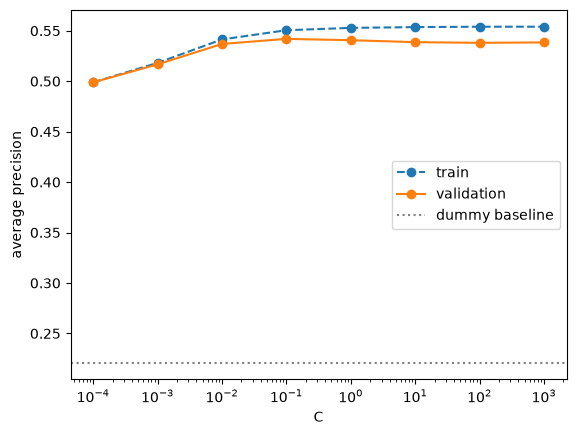

In [24]:
none = lr_results[lr_results["param_logisticregression__class_weight"].isna()]
C = none["param_logisticregression__C"].astype(float)

plt.semilogx(C, none["mean_train_average_precision"], "--o", label="train")
plt.semilogx(C, none["mean_test_average_precision"], "-o", label="validation")
plt.axhline(0.221, color="gray", linestyle=":", label="dummy baseline")
plt.xlabel("C")
plt.ylabel("average precision"); plt.legend()

Best: C = 0.1, AP is 0.542 $\pm$ 0.014, which is well above our threshold from the dummy of 0.221. 

Small C underfits: At C = 0.0001, the regularization is so strong that train and validation are both lower, at 0.499. 

Anything beyond 0.01, the curve is just flat. Everything from C = 0.01 to C = 1000 sits well within about 0.005 of the best, which is less than one STD away. Any C in that range is effectively just as good. Choosing exactly C=0.1 is fine here, but its not clearly better than say C = 1. 

No overfitting: The train-validation gap is only around 0.01 even at C=1000. the linear model's limit is underfitting, not overfitting. It can't capture the interactions or non linear effects of these features. 

The class_weight findings proves the metric discussion from before. Ap barely changes etween None and "balanced"(0.542 vs 0.54), because AP measures ranking, and reweighting the classes barely changes the order of clients by risk. F1 also jumps from around 0.46 to 0.54 with "balanaced", which in effect lowers the decision threshold, so recall will go up. F1 is evaluated at one threshold only, so its sensitive to that, and AP here isnt. 

Fit time: pretty fast, under a second per fit, and it grows with C. this makes sense as weaker regularization takes the solver more iterations to converge. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 8. Different models <a name="8"></a>
<hr>
rubric={points:12}

**Your tasks:**
1. Try at least 3 other models aside from a linear model. One of these models should be a tree-based ensemble model. 
2. Summarize your results in terms of overfitting/underfitting and fit and score times. Can you beat a linear model? 

<div class="alert alert-warning">
    
Solution_8
    
</div>

_Points:_ 12

Okay! Looking through the models that we have learned so far, we have Random forest, LightGBM, RBF SVM, kNN, and decision trees. since we need a tree based ensemble model, I will just make a simple decision tree as a reference point, to show how much the ensemble improves on one singlar tree. Now we implment! all are set to random-state=123, n_jobs=-1 for all available core use, and verbose so we dont clog our output. 

In [25]:
models = {
    "decision tree": DecisionTreeClassifier(random_state=123),
    "kNN": KNeighborsClassifier(),
    "RBF SVM": SVC(random_state=123),
    "random forest": RandomForestClassifier(random_state=123, n_jobs=-1),
    "LightGBM": LGBMClassifier(random_state=123, verbose=0)
}

for name, model in models.items(): 
    pipe = make_pipeline(preprocessor, model)
    results[name] = cv_summary(pipe, X_train, y_train)

Okay so now that we have all of our models ran through the same preprocessor and written into results, we can pull them out below and write out a quick summary.

In [26]:
summary = pd.DataFrame({
    name: {
        "train AP": r.loc["train_average_precision", "mean"], 
        "validation AP": r.loc["test_average_precision", "mean"],
        "validation AP std": r.loc["test_average_precision", "std"],
        "validation F1": r.loc["test_f1", "mean"],
        "fit time (s)": r.loc["fit_time", "mean"],
        "score time (s)": r.loc["score_time", "mean"],
    }
    for name, r in results.items()
}).T

summary

,train AP,validation AP,validation AP std,validation F1,fit time (s),score time (s)
dummy,0.221,0.221,0.000,0.000,0.008,0.011
decision tree,1.000,0.289,0.008,0.397,0.295,0.022
kNN,0.642,0.421,0.012,0.434,0.028,0.725
RBF SVM,0.656,0.519,0.021,0.457,17.990,4.078
random forest,1.000,0.528,0.008,0.468,0.953,0.112
LightGBM,0.765,0.547,0.013,0.465,0.947,0.034


now we analyze

Nice to note here that I am not doing any Hyperparam optimizations and using the base models because question 10 below asks for hyperparam optimizations. Therefore most statements below are based off the defualt settings. 

Overfitting: 
- the decision tree and random foreest both have a train AP of 1.000. unrestriced tree here just memorizes the training data. The single tree is hurt pretty badly from this, giving us 0.289 val AP, which is only slighly above the dummy of 0.221. The forest still does pretty well at 0.528, becuase averaging many varied trees cancels out alot of the variance here. Thats the basic idea of ensembles i think
- kNN (0.64 vs 0.42) and the SVM (0.66 vs 0.52) have pretty decent gaps, clearly overfitting abit with defualt settings
- LightGBM has a prettu big gap too at (0.77 vs 0.547), but it does have the best validation score of the group so far. finally the logistic regressor has basically no gap, its the most stable so far, and its limited by bias

Times: 
- kNN is the classic fast learner since it just copies over the entire training set, and then its the slowest to score out of the faster models, since it has to compare each validation point to the whole training set. 
- the SVM is by far the slowest at both fitting and scoring which also makes sense, they should be growing quadratically or cubicly since they need to compute a kernel matrix 
- LightGBM is about as fast as the logistic regressor. 

Can we beat the linear model? 
Barely. without tuning here, LightGBM's 0.547 vs LR's 0.542 is basically just nothign sicne its under one std. so right now theyre effectively the same thing, tied. The non linear models are untuned though, so there is alot of room to grow from here. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 9. Feature selection <a name="9"></a>
<hr>
rubric={points:2}

**Your tasks:**

Make some attempts to select relevant features. You may try `RFECV` or forward selection for this. Do the results improve with feature selection? Summarize your results. If you see improvements in the results, keep feature selection in your pipeline. If not, you may abandon it in the next exercises. 

<div class="alert alert-warning">
    
Solution_9
    
</div>

_Points:_ 2

We definetly have afew features that are not too useful, such as Rare one hot columns like PAY_6 = 8, which happens only a handful of times, along with redunant features like the six BIll_AMT, tehy are all correlated at about 0.8 to 0.95 as mentioned before in my EDA, Visualization 2. Dropping these may reduce overfitting, speed up training and prediction, and it could make the model easier to interpret. And so we try them out. 

Afew details to keep in mind here: 
RFECV goes inside of the pipeline since selecting features is learning from the data, just like fitting a scalar. If we ran it on all of X_train first and then we crossvalidated, each validation fold would influence which features were kept. This is leaking data, and it makes the scores optimistic. so in the pipeline, each outer CV fold reruns the selection on its own training part. 

We are using the tuned value of C=0.1 here for the logistic regressor. This was our best model and best described model so far, and its coefficients give us a natural importance ranking that we can use. For tree models we would rank by feature_importance insteead but trees already ignore useless features, so the gain would be alot less there compared to LR

I ran step = 5 here since removing one feature at a time would take 89 rounds and i do not have the time for that, even 5 steps took 6 minutes to run with 22 cores. 

In [27]:
from sklearn.feature_selection import RFECV

pipe_rfe = make_pipeline(
    preprocessor,
    RFECV(
        LogisticRegression(C=0.1, max_iter=3000, random_state=123),  # ranks features by the coefficient
        step=5,                          # drop 5 features per round
        scoring="average_precision",     # choose the feature count by AP 
    ),
    LogisticRegression(C=0.1, max_iter=3000, random_state=123),      # final model on the kept features
)
results["logreg + RFECV"] = cv_summary(pipe_rfe, X_train, y_train)
results["logreg + RFECV"]

,mean,std
fit_time,6.444,0.486
score_time,0.025,0.003
test_average_precision,0.542,0.015
train_average_precision,0.550,0.004
test_f1,0.459,0.016
train_f1,0.464,0.007
test_accuracy,0.818,0.005
train_accuracy,0.819,0.001


Now we can look at the curves, fitting only on the training set, to see why the results come out the way it does. Here we can see that we dropped 15 features, mostly all rare PAY_* one hot levels and BILL_AMT2 and PAY_AMT6. 

There was basicaly no improvemnet. AP is still 0.542 with and without selection, so nothing has changed. By the question above, we will abandon it. 

Now why would it not help much? 
- regularization already does a softer version of this. with C=0.1, we are already shrinking thhe coefficients of weal features toward 0, so they barely affect the predictions anyway. Removing them would do little to nothing if not just cause noise
- the dropped features are what we expected above. rare PAY_* levels with too few rows to learn from, and BILL_AMT2 which is redundant with it's neighbouring months. This was a good proof of our EDA's correlation finding! 

Something cool to note here is that 14-15 features basically keeps us afloat for this model. AP rises very steeply there and then plateaus quickly. The other 75 features add basically nothing to the AP, looks like its less than one fold's STD. If the interprebility mattered for this model, we could consider dropping down to less features

the Selection itself is also rpetty unstable. In the outer CV folds, RFECV kept 49, 86, 54, 73 and 69 feautres. This is becuase the curve itself is so flat past around 30 features that many feature counts probably score within some noise of eachother. 

We are dropping it since it ups my fit time by like 18 times for literally no gain. 

features kept: 74
dropped: ['standardscaler__BILL_AMT2', 'standardscaler__PAY_AMT6', 'onehotencoder-1__PAY_2_-2', 'onehotencoder-1__PAY_3_-2', 'onehotencoder-1__PAY_3_3', 'onehotencoder-1__PAY_3_8', 'onehotencoder-1__PAY_4_1', 'onehotencoder-1__PAY_4_4', 'onehotencoder-1__PAY_5_-2', 'onehotencoder-1__PAY_5_6', 'onehotencoder-1__PAY_5_8', 'onehotencoder-1__PAY_6_-2', 'onehotencoder-1__PAY_6_5', 'onehotencoder-1__PAY_6_6', 'onehotencoder-1__PAY_6_8']


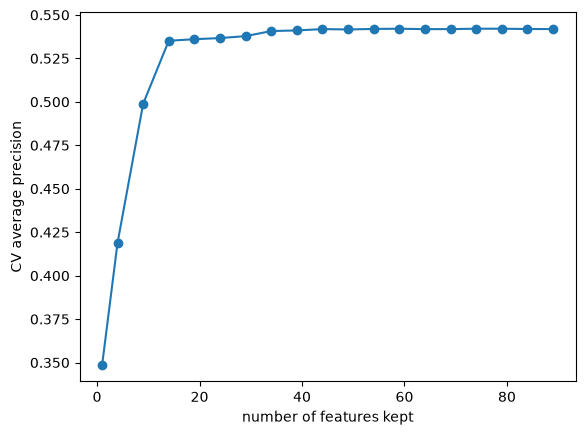

In [28]:
pipe_rfe_fit = make_pipeline(
    preprocessor,
    RFECV(LogisticRegression(C=0.1, max_iter=3000, random_state=123),
          step=5, scoring="average_precision"),
)
pipe_rfe_fit.fit(X_train, y_train)
rfecv = pipe_rfe_fit.named_steps["rfecv"]

plt.plot(rfecv.cv_results_["n_features"], rfecv.cv_results_["mean_test_score"], "-o")
plt.xlabel("number of features kept"); plt.ylabel("CV average precision");

print("features kept:", rfecv.n_features_)
feature_names = pipe_rfe_fit.named_steps["columntransformer"].get_feature_names_out()
print("dropped:", list(feature_names[~rfecv.support_]))

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 10. Hyperparameter optimization <a name="10"></a>
<hr>
rubric={points:10}

**Your tasks:**

Make some attempts to optimize hyperparameters for the models you've tried and summarize your results. In at least one case you should be optimizing multiple hyperparameters for a single model. You may use `sklearn`'s methods for hyperparameter optimization or fancier Bayesian optimization methods. 
  - [GridSearchCV](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)   
  - [RandomizedSearchCV](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
  - [scikit-optimize](https://github.com/scikit-optimize/scikit-optimize) 

<div class="alert alert-warning">
    
Solution_10
    
</div>

_Points:_ 10

So we already tuned LR in section 7, now we tune the rest. 

| Model | Search | Why this kind |
|-------|--------|---------------|
| Decision tree | Grid, 2 hyperparam | Small, discrete space |
| kNN | Grid, 2 hyperparam | Small, discrete space | 
| Random Forest | Randomized, 4 hyper param | Too many combinations for grid | 
| LightGBM | Randomizeed, 8 hyperparam | WAYY too many combinations to grid, and several are continous |

I will not be tuning SVM since at around 30s a fit, a 3x3 grip over C and gamma with 5 folds is 45 fits, coming out to 20 minutes. The default score was already pretty low too.

Every randomized run is used with random_state_123, so my results are reproducable. 

In [29]:
searches = {} 

def top_results(search, n=5):
    """Top-n hyperparameter settings by validation AP"""
    cols = [c for c in search.cv_results_ if c.startswith("param_")]
    cols += ["mean_train_score", "mean_test_score", "std_test_score", "mean_fit_time"]
    return (pd.DataFrame(search.cv_results_)[cols].sort_values("mean_test_score", ascending=False).head(n).round(3))

In [30]:
dt_grid = {
    "decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, 10, 15, None],
    "decisiontreeclassifier__min_samples_leaf": [1, 20, 50, 100], # min rows per leaf bigger = smoother
}
searches["decision tree"] = GridSearchCV(
    make_pipeline(preprocessor, DecisionTreeClassifier(random_state=123)),
    dt_grid, scoring="average_precision", return_train_score=True, n_jobs=-1,
).fit(X_train, y_train)
top_results(searches["decision tree"])

,param_decisiontreeclassifier__max_depth,param_decisiontreeclassifier__min_samples_leaf,mean_train_score,mean_test_score,std_test_score,mean_fit_time
19,6,100,0.557,0.525,0.012,0.271
23,8,100,0.575,0.523,0.014,0.308
27,10,100,0.581,0.523,0.013,0.300
31,15,100,0.584,0.523,0.013,0.325
35,None,100,0.584,0.523,0.013,0.273


In [31]:
knn_grid = {
    "kneighborsclassifier__n_neighbors": [5, 10, 25, 50, 100, 200], #bigger k = smoother, less overfitting
    "kneighborsclassifier__weights": ["uniform", "distance"], # distance gives us closer neighbours count more
}
searches["kNN"] = GridSearchCV(
    make_pipeline(preprocessor, KNeighborsClassifier()),
    knn_grid, scoring="average_precision", return_train_score=True, n_jobs=-1,
).fit(X_train, y_train)
top_results(searches["kNN"])

,param_kneighborsclassifier__n_neighbors,param_kneighborsclassifier__weights,mean_train_score,mean_test_score,std_test_score,mean_fit_time
9,100,distance,1.000,0.521,0.011,0.059
8,100,uniform,0.539,0.520,0.012,0.053
7,50,distance,1.000,0.519,0.012,0.055
10,200,uniform,0.528,0.518,0.016,0.092
11,200,distance,1.000,0.518,0.013,0.066


In [32]:
rf_dist = {
    "randomforestclassifier__n_estimators": randint(100, 500), # number of trees
    "randomforestclassifier__max_depth": [4, 6, 8, 10, 15, 20, None],# depth limit per tree
    "randomforestclassifier__min_samples_leaf": randint(1, 50), # minimun rows per leaf
    "randomforestclassifier__max_features": ["sqrt", 0.3, 0.5], # features considered at each split
}
searches["random forest"] = RandomizedSearchCV(
    make_pipeline(preprocessor, RandomForestClassifier(random_state=123, n_jobs=1)),
    rf_dist, n_iter=20, scoring="average_precision", return_train_score=True,
    n_jobs=-1, random_state=123,
).fit(X_train, y_train)
top_results(searches["random forest"])

,param_randomforestclassifier__max_depth,param_randomforestclassifier__max_features,param_randomforestclassifier__min_samples_leaf,param_randomforestclassifier__n_estimators,mean_train_score,mean_test_score,std_test_score,mean_fit_time
17,8,sqrt,7,370,0.636,0.556,0.013,14.485
2,10,0.3,23,325,0.667,0.555,0.011,32.587
10,None,0.3,22,218,0.704,0.555,0.010,24.081
5,6,0.5,37,196,0.601,0.554,0.011,21.643
13,10,0.5,11,378,0.720,0.554,0.012,63.473


In [33]:
lgbm_dist = {
    "lgbmclassifier__n_estimators": randint(50, 600),# number of boosting rounds
    "lgbmclassifier__learning_rate": loguniform(0.01, 0.3),# how much each tree corrects the previous ones
    "lgbmclassifier__num_leaves": randint(8, 64), # tree complexity
    "lgbmclassifier__min_child_samples": randint(10, 200), # min rows per leaf
    "lgbmclassifier__subsample": uniform(0.6, 0.4),# fraction of rows per tree, 0.6 to 1.0
    "lgbmclassifier__subsample_freq": [1],# needed for subsample to take effect
    "lgbmclassifier__colsample_bytree": uniform(0.5, 0.5),# fraction of features per tree: 0.5 to 1.0
    "lgbmclassifier__reg_lambda": loguniform(1e-3, 10), # L2 regularization
}
searches["LightGBM"] = RandomizedSearchCV(
    make_pipeline(preprocessor, LGBMClassifier(random_state=123, verbose=-1, n_jobs=1)), # we use n_jobs=1 here that way we dont get oversubscription
    lgbm_dist, n_iter=40, scoring="average_precision", return_train_score=True,
    n_jobs=-1, random_state=123,
).fit(X_train, y_train)
top_results(searches["LightGBM"])

,param_lgbmclassifier__colsample_bytree,param_lgbmclassifier__learning_rate,param_lgbmclassifier__min_child_samples,param_lgbmclassifier__n_estimators,param_lgbmclassifier__num_leaves,param_lgbmclassifier__reg_lambda,param_lgbmclassifier__subsample,param_lgbmclassifier__subsample_freq,mean_train_score,mean_test_score,std_test_score,mean_fit_time
29,0.564,0.013,24,585,36,0.003,0.681,1,0.743,0.556,0.012,4.097
14,0.955,0.021,78,536,9,0.001,0.722,1,0.626,0.556,0.013,2.365
34,0.652,0.053,29,343,9,1.476,0.807,1,0.653,0.556,0.014,1.667
13,0.778,0.017,25,365,48,0.003,0.805,1,0.764,0.555,0.013,3.200
19,0.915,0.032,27,138,54,0.210,0.724,1,0.729,0.555,0.014,1.670


In [34]:
for name, s in searches.items():
    print(f"{name}: best CV AP = {s.best_score_:.3f}  {s.best_params_}")
    results[f"{name} (tuned)"] = cv_summary(s.best_estimator_, X_train, y_train)

decision tree: best CV AP = 0.525  {'decisiontreeclassifier__max_depth': 6, 'decisiontreeclassifier__min_samples_leaf': 100}
kNN: best CV AP = 0.521  {'kneighborsclassifier__n_neighbors': 100, 'kneighborsclassifier__weights': 'distance'}
random forest: best CV AP = 0.556  {'randomforestclassifier__max_depth': 8, 'randomforestclassifier__max_features': 'sqrt', 'randomforestclassifier__min_samples_leaf': 7, 'randomforestclassifier__n_estimators': 370}
LightGBM: best CV AP = 0.556  {'lgbmclassifier__colsample_bytree': np.float64(0.56431559875469), 'lgbmclassifier__learning_rate': np.float64(0.013206845730310994), 'lgbmclassifier__min_child_samples': 24, 'lgbmclassifier__n_estimators': 585, 'lgbmclassifier__num_leaves': 36, 'lgbmclassifier__reg_lambda': np.float64(0.003083004783247143), 'lgbmclassifier__subsample': np.float64(0.6805598005525484), 'lgbmclassifier__subsample_freq': 1}


Overall results: 

| Model | Default val AP | Tuned Val AP ($\pm$ std) | Train AP (tuned) | Best settings | 
|-------|----------------|--------------------------|------------------|---------------|
| Decision Tree | 0.289 | $0.525 \pm 0.012$ | 0.557 | max_depth=6, min_samples_leaf=100 |
| kNN | 0.421 | $0.521 \pm 0.11 | 1.000* | n_neighbours=100, weights="distance" | 
| Logistic regression (section 7) | -- | $0.542 \pm 0.014$ | 0.551 | C=0.1 |
| Random Forest | 0.528 | $0.556 \pm 0.013$ | 0.636 | max_depth=8, min_samples_leaf=7, max_features="sqrt", 370 trees |
| LightGBM | 0.547 | $0.556 \pm 0.012$ | 0.743 | 585 trees, learning_rate≈0.013, num_leaves=36, and others |

Tuning fixed the overfitting in each model
- the decision tree improved the most in this regard. limiting the depth to 6 and requiring 100 rows per leaf stopped it from memorizing the data, and its train AP dropped from 1.000 to 0.557. Thats regularization! 
- the random forest did pretty good too, AP from 1.000 to 0.636 with max_depth=8 and min_samples_leaf=7, and its validation AP rose to 0.556 from 0.528. 
- kNN also improved with much larger K(100 instead of 5). 

LightGBM and the random forest tied for the best, at 0.556 AP. that is 0.014 above LR, whcih is about one STD away. So the tuned tree ensembles beat the linear model but by a small amount. THis is consistent with our prediction where most of the signals are fro mthe repayment history, which a linear model captures well. 

*kNN's train AP of 1.000 is not overfitting here, its just an artifact. With weights="distance", every training point is it's own nearest neighbour at distance 0, so it gets infinite weight, and hte prediction for a training point is just its own label. so here the validation score is the honest number we hsould look at. the "uniform" version with k=100 scores nearly the same at 0.52, with a normal train score of 0.539
The tops of the searches are basically flat. LightGBM's five best settings are all within 0.0015 of eachother and the forest's 0.0016, far less than the std of about 0.012. this menas that the exact best hyper param arnt meaningful, many settings perform equally as well, and thte best one barely comes out on top. 

The final model we pcik ehre would be LightGBM. It ties the random forest on AP but it is must faster in fitting and scoring. We prefer the cheaper and simpler model when scores tie. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 11. Interpretation and feature importances <a name="1"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Use the methods we saw in class (e.g., `eli5`, `shap`) (or any other methods of your choice) to examine the most important features of one of the non-linear models. 
2. Summarize your observations. 

<div class="alert alert-warning">
    
Solution_11
    
</div>

_Points:_ 10

SHAP 

for each client, SHAP basically splits the model's prediction into a contribution from each feature. kind like how a linear model adds up its weights, we have a base or intercept, and then we add up the other features. so here for lightGBM, the units are log odds, the raw score before the sigmoid, as in lr. positive means more likely to default while negative means less likely. averaging the size of each feature's SHAP values across all clients gives us a global feature importance. looking at the individual clients gives us explinations of single predictions. 

In [35]:
best_lgbm = searches["LightGBM"].best_estimator_
ct = best_lgbm.named_steps["columntransformer"]
lgbm = best_lgbm.named_steps["lgbmclassifier"]

feature_names = [name.split("__")[1] for name in ct.get_feature_names_out()]  # drop "standardscaler__" etc...
X_train_enc = pd.DataFrame(ct.transform(X_train), columns=feature_names, index=X_train.index)

explainer = shap.TreeExplainer(lgbm) # fast, exact SHAP for tree models
shap_values = explainer(X_train_enc)#about a minute; use X_train_enc.sample(2000, random_state=123) if slow

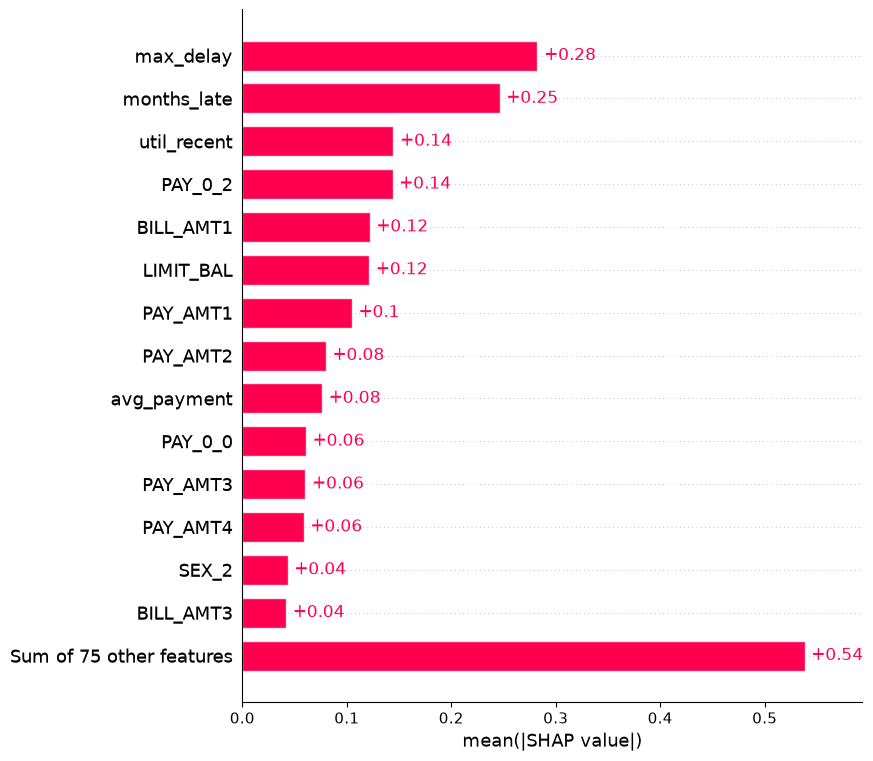

In [36]:
shap.plots.bar(shap_values, max_display=15) # here we have the bar plot global importance

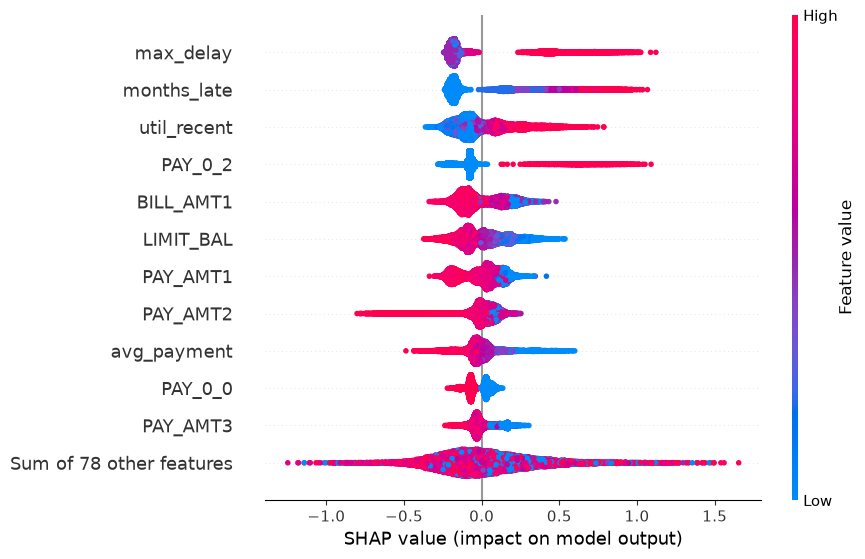

In [37]:
shap.plots.beeswarm(shap_values, max_display=12) #here we have the beeswarm plot

Results: 

| Rank | Feature | Mean shap | What it is | 
|------|---------|-------------|------------|
| 1 | max_delay | 0.283 | engineered: worst delay in 6 months |
| 2 | months_late | 0.246 | engineered: number of late months |
| 3 | util_recent | 0.145 | engineered: bill / credit limit |
| 4 | PAY_0_2 | 0.144 | 2 months late in September |
| 5 | BILL_AMT1 | 0.122 | September bill |
| 6 | LIMIT_BAL | 0.121 | credit limit |
| 7 | PAY_AMT1 | 0.105 |September payment |
| 8 | PAY_AMT2 | 0.080 |August payment |
| 9 | avg_payment | 0.076 | engineered |
| ... | SEX_2 | 0.043(13th) | 
| ... | AGE | 0.04(15th) | 


So what does the beeswarm show us? 

red = high feautre value, blue = low 
- max_delay, months_late, PAY_0_2 are all high vlaues that sit far to the right, up to 1.0 log odds or more. More and longer late payments mena a much higher default risk. low value scluster just left of 0
- util_recent has high utilization, pushes toward default. clients near their credit limits are riskier than those futher away
- LIMIT_BAL shows us another high limit pushes left, toward lower risk. this matches our EDA, where default rates fell from 31% to 14% across limit quartiles 
- PAY_AMT1, PAY_AMT2, avg_payment show us that larger payments push toward lower risks. clients that pay down their balance are usually safer 
- finally, BILL_AMT1 is a larger bill, given the other features, and pushes sligihtly toward lower risk. This is a conditional effect. Utilization already captures "bill is large relative to the limit", so once thats accounted for, a large raw bill mostly just signals an active customer with a high limit. 

so overall: 

1. Replayment history dominates. The top two features are PAY_0_2 all describe late payments, which matches my EDA and the hypothesis in section 1! 
2. The feature engineering paid off. There of the top four feataures, meaning(may_delay, months_late, util_recent) are ones that we created in section 4 together. The model found that these were more useful than the raw columns that they were built from. its the best evidence we have here that section 4 was worth doing
3. the effects of our research makes sense too. Late payments and high utilization raise risk, while high limits and large payments lower it. a model whose explinations agree with intuition is easier and simpler to understand and trust 
4. Demographics dont matter much. SEX_2 and AGe contirbute far less to the model than payment behaviour does. They arnt zero though, which ties back to the fairness concern we raised in section 1. if this model was to be used for real lending decisions, any effects of features such as sesx would need scrutiny
5. Overall we fit hte RFECV result. in section 9 we found that about 14 features gave almost all the performance, and here a handle of payment history and utilization features are carrying most of the SHAP importance
6. Afew small caveats: 
- SHAP describbes what the model uses, not what causes the defaults 
- correlated features share credit. max_delay, months_late and the PAY_* columns overlap quite abit, so their importanaces are split among them. 
- the vlaues are in log-odds on the log transformed and scaled features so "higher" and "lower" are all relative to eachother, not raw dollars so we have no unit or scalaing issues here! 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 12. Results on the test set <a name="12"></a>
<hr>

rubric={points:10}

**Your tasks:**

1. Try your best performing model on the test data and report test scores. 
2. Do the test scores agree with the validation scores from before? To what extent do you trust your results? Do you think you've had issues with optimization bias? 
3. Take one or two test predictions and explain these individual predictions (e.g., with SHAP force plots).  

<div class="alert alert-warning">
    
Solution_12
    
</div>

_Points:_ 10

This is the first time we are touching the test set. 

In [38]:
best_lgbm = searches["LightGBM"].best_estimator_# already refit

test_proba = best_lgbm.predict_proba(X_test)[:, 1] # P(default), needed for AP
test_pred = best_lgbm.predict(X_test) # hard 0/1 at threshold 0.5, for F1 etc.

test_scores = pd.Series({
    "average precision": average_precision_score(y_test, test_proba),
    "F1": f1_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "accuracy": best_lgbm.score(X_test, y_test),
}).round(3)
test_scores

average precision    0.573
F1                   0.479
precision            0.685
recall               0.369
accuracy             0.823
dtype: float64

In [39]:
confusion_matrix(y_test, test_pred)# row - true class, columns - predicted class

array([[6671,  338],
       [1257,  734]])

In [40]:
#running shap on the test set 
X_test_enc = pd.DataFrame(ct.transform(X_test), columns=feature_names, index=X_test.index)
shap_test = explainer(X_test_enc)

# Pick two interesting test clients: a default the model caught, and one it missed
test_results = pd.DataFrame({"true": y_test.values, "proba": test_proba})
i_hit = test_results[(test_results["true"] == 1) & (test_results["proba"] > 0.7)].index[0]
i_miss = test_results[(test_results["true"] == 1) & (test_results["proba"] < 0.2)].index[0]

true     1.000000
proba    0.764636
Name: 26, dtype: float64


LIMIT_BAL    110000.0
AGE              32.0
PAY_0             2.0
PAY_2             2.0
PAY_3             2.0
PAY_4             2.0
PAY_5             2.0
PAY_6             2.0
BILL_AMT1     95686.0
PAY_AMT1       5100.0
PAY_AMT2       3700.0
Name: 9107, dtype: float64

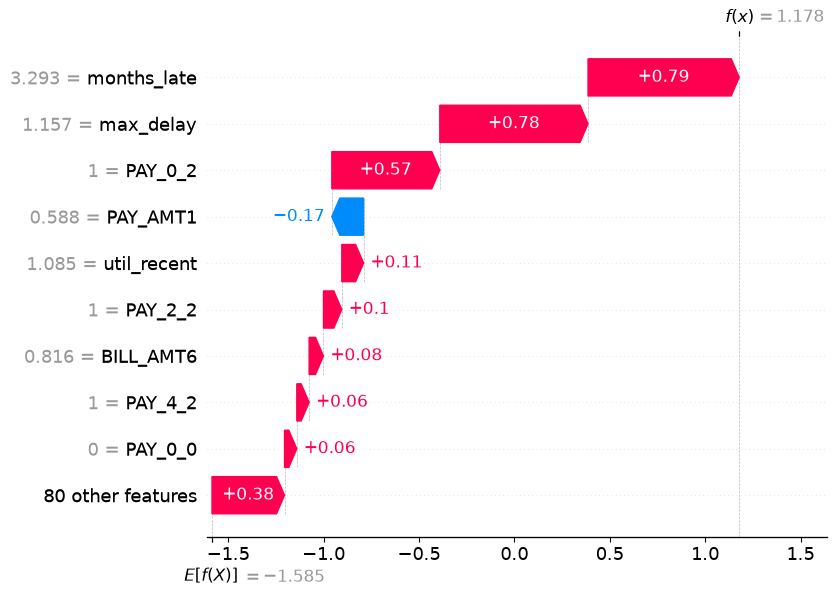

true     1.000000
proba    0.169504
Name: 27, dtype: float64


LIMIT_BAL    20000.0
AGE             24.0
PAY_0            0.0
PAY_2            0.0
PAY_3            0.0
PAY_4            0.0
PAY_5            0.0
PAY_6            0.0
BILL_AMT1     6215.0
PAY_AMT1      1300.0
PAY_AMT2      1500.0
Name: 26586, dtype: float64

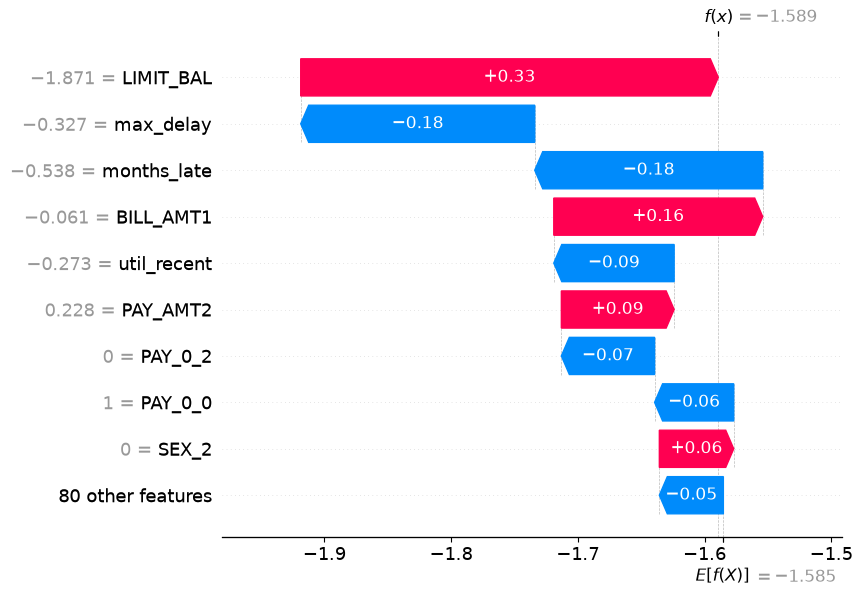

In [41]:
raw_cols = ["LIMIT_BAL", "AGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
            "BILL_AMT1", "PAY_AMT1", "PAY_AMT2"]

print(test_results.loc[i_hit])
display(df.loc[X_test.index[i_hit], raw_cols])
shap.plots.waterfall(shap_test[i_hit], max_display=10)

print(test_results.loc[i_miss])
display(df.loc[X_test.index[i_miss], raw_cols])
shap.plots.waterfall(shap_test[i_miss], max_display=10)

Results: 
Test scores vs validation 

| Metric | CV (training set) | Test |
|--------|-------------------|------|
| Average precision | $0.556 \pm 0.012$ | 0.573 |
| F1 | (from results table) | 0.479 |
| Precision | | 0.685 |
| Recall | | 0.369 |
| Accuracy | | 0.823 |
| Dummy AP, for reference | 0.221 | 


Confusion Matrix(test, 9000 clients) 

| |Predicted no default|Predicted default| 
|-|--------------------|-----------------|
| Actually no default | 6 671 | 338 |
| Actually defaulted | 1 257 | 734 |


Client 1(i_hit): 
A default that the model caught. P(default)=0.765 and they did default
- Raw data: two months late in every one of the 6 months PAY_0 to PAY_6, a 110,000 limit, and a bill of 95,686(87% of the limit). 
- The waterfall starts at the base value of -1.585 log odds(the average client) and ends at 1.18(about 77%). the biggest pushes came from months_late and max_delay for 0.79 and 0.78 respectively. PAY_0_2 +0.57 two months late most recently, util_recent +0.11, close to the limit, and PAY_AMT1 -0.17, the one thing in their favor, they paid 5,100 last month. 
- overall this explination makes sense. a consistent run of late payments is thee strongest risk signal in the data, and the model treats it that way

client 2(i_miss): 
a default that the model missed. P(default) = 0.17, but they did default 
- Raw data: PAY_0 and PAY_6 all 0, so they didnt miss a single payment, and a 20,000 limit, a bill of 6215, regular payments of 1300 to 1500
- the SHAPE vlaues roughly cancel eachother out, and the prediction ends almost exactly at the base value. LIMIT_BAL 0.33 sincea very low limit means higher risk, max_delay -0.19 and months_late -0.18 since a clean payment histroy means lower risk, and BILL_AMT1 +0.17 and util_recent -0.1
- why the model missed: nothing in this client's six months of history signals bad trouble. they never paid late, and they kept paying. the only warning sign is the low limit. a default here probably comes from something outside of the written data, maybe like loosing a job, so no models built on these features could reasonably flag this person. This is a limitation of the data and not the model, so its worth considering

Final thoughts: 
1. do the test and validation agree? Yes they do. Test AP(0.573) is close to CV AP (0.556) and in fact slightly higher, a difference of about 1.4 fold STD. Two reasons that i could think of could be the cause: 
- the final model was trained on all 21,000 training rows, while each CV fold trained only on 80% of them. more data usually helps alittle
- the test set is one random sample of 9,000 clients, so some variation either way is expected
2. Optimization bias: we searched for around 40 different LightGBM configurations and kept the best CV score, which can inflate that score. If that had happened in a bad way, then the test score could come out below the CV score. it didnt though, which suggests that the bias was small. This fits section 10's findings that the top of the search was flat: there was no lucky outlier to overfit to. we also only used the test set once, at the end, with no choices based on it, which is what keeps this number more trustworthy. 
3. how much to trust it? quite abit. It's consistent with CV, its 2.6 times the dummy baseline, the test set was untouched until now, and the explinations make sense. the caveat is that its still one train test split from one bank in 2005, so it wont generalized too well world wide id assume, which is mentioned in section 1. 
4. the recall problem which is worth highlighting: at the default 0.5 theshold, we see that the model only catches 37% of defaulters(734/1991), but when it does flag someone, its right 68% of the time. for a bank, missing a defaulter usually would cost more than a false alarm, so in practice i think we would lower the threshold to get more defualts at hte cost of more false alarms. AP was chosen as the main metric becuase it doesnt depend on this threshold. Choosing the threshold properly would need the bank's cost benefit analysis on defualts vs false defaults and should be done on validation data. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 13. Summary of results <a name="13"></a>
<hr>
rubric={points:12}

Imagine that you want to present the summary of these results to your boss and co-workers. 

**Your tasks:**

1. Create a table summarizing important results. 
2. Write concluding remarks.
3. Discuss other ideas that you did not try but could potentially improve the performance/interpretability . 
3. Report your final test score along with the metric you used at the top of this notebook in the [Submission instructions section](#si).

<div class="alert alert-warning">
    
Solution_13
    
</div>

_Points:_ 12

We start with a summary table, that is build from our previous results dict. This is the same code from section 8, now sorted and it picks up everything weve added since, including but not limited to the tuned models, RFECV, etc. 

In [42]:
summary = pd.DataFrame({
    name: {
        "train AP": r.loc["train_average_precision", "mean"],
        "val AP": r.loc["test_average_precision", "mean"],
        "val AP std": r.loc["test_average_precision", "std"],
        "val F1": r.loc["test_f1", "mean"],
        "fit time (s)": r.loc["fit_time", "mean"],
    }
    for name, r in results.items()
}).T.sort_values("val AP", ascending=False)
summary

,train AP,val AP,val AP std,val F1,fit time (s)
random forest (tuned),0.636,0.556,0.014,0.467,5.037
LightGBM (tuned),0.743,0.556,0.013,0.471,1.335
LightGBM,0.765,0.547,0.013,0.465,0.947
logreg + RFECV,0.550,0.542,0.015,0.459,6.444
random forest,1.000,0.528,0.008,0.468,0.953
decision tree (tuned),0.557,0.525,0.013,0.455,0.139
kNN (tuned),1.000,0.521,0.012,0.413,0.031
RBF SVM,0.656,0.519,0.021,0.457,17.990
kNN,0.642,0.421,0.012,0.434,0.028
decision tree,1.000,0.289,0.008,0.397,0.295


| Model | Validation AP (5-fold CV) | Notes |
|-------|---------------------------|-------|
|Dummy (baseline) | 0.221 | Predicts no default for everyone, 78% accuracy but useless |
| Logistic regression (C=0.1)| $0.542 \pm 0.014 $| Stable, no overfitting, fast |
|Decision tree (tuned) | $0.525 \pm 0.012 $| 0.289 untuned, limiting the depth fixed severe overfitting |
|kNN (tuned, k=100)| $0.521 \pm 0.011$|Slow to predict| 
|RBF SVM (default)| $0.519 \pm 0.021$|Slowest by far, not tuned because it was so slow|
|RandomForest(tuned)| $0.556 \pm 0.013$|Ties for the best; slower to fit|
|LightGBM (tuned)| $0.556 \pm 0.012$|Final model, ties for the best, but fast| 
|LightGBM on the test set| AP 0.573|F1 0.479, Precision 0.685, recall 0.369| 

Feature selection(RFECV) gave no gains(0.542 with or without it), so it was dropped. 

Concluding Remarks: 
- The final model is tuned LightGBM, with test AP 0.573, about 2.6 times the baseline, and consistent with it's CV score(0.556). No sign of serious optimization bias. 
- Tree ensembles beat logistic regression, but only by abit(0.556 vs 0.542, about one STD). Most of the signal is simple enough for a linear model to capture by itself
- Repayment history is the key signal. SHAP ranked max_delay, months_late and PAY_0_2 at the top, consistent with our EDA. Three of the top four features were engineered, so feature engineering was amoung the most useful steps that we made in the project! 
- Preprocessing choices mattered for the linear model. one hot encoding PAY_* rather than treating it as numerical raise our AP from 0.51 to 0.54
- Accuracy would have been misleading to read and rely on here since the summy gets 78% accuracy, while the final model's 82% sounds only slightly better, its AP is 2.6 times bigger
- Limitations! at the default theshold, recall is only at 37%, so the model misses most of its defaulters. some defaults are unpredictable from this data, like the test client with a prefect payment history who defaulted anyways 

Some ideas that I didnt try: 
- There are many many that I can think of so I will list them out here with a small description. 
Tune the decision theshold using the bank's real costs(a missed defaulter vs a false alarm), on validation data. This would raise our recall
- Probability calibration. Reading over the paper, its main focus was estimating the actual probability of default, not just ranking clients. checking whether a predicted 0.3 really means a 30% default rate(ex. CalibratedClassiferCV) would matter for pricing risk 
- More feature engineering: trends over time such as bill growth, whether payments are rising or falling, payments to bill ratios per month, and thel ength of the current late payment streak
- Ensembles of different models: voting or stacking logistic regression, the random forest and LightGBM, as in our ensembles tutorial. They could definitely make different types of mistakes, so combining them might help. 

<!-- END QUESTION -->

<br><br>

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 14. Your takeaway <a name="15"></a>
<hr>
rubric={points:2}

**Your tasks:**

What is your biggest takeaway from the supervised machine learning material we have learned so far? Please write thoughtful answers.  

<div class="alert alert-warning">
    
Solution_14
    
</div>

_Points:_ 2

I walked into this course with an engineering physics background and zero ML experince, I didnt even know the difference between model types such as ML vs MV vs LLMs. Overall it has been very very interesting learning about how these models function, but with a black box covering implementations, that way we are able to utilize the models and apply our thinking to real world problems. I have afew details id like to add on. 

1. This is very similar to a project I did for formula electric, fitting pacejka coefficients with least square approximations to grab equation coefficients(context: pacejka is a model that matches measureable tire params to tire forces). I was also preprocessing thousands of tire datapoints, and then minizing a squared error loss, which is basically exactly what fit does for linear regressors. The big differences came from where the model's shapes come from: 
- Pacejka: physics and decades of tire research fixed the formula, and you only fit a handful of coefficients. Its very interpretable and extrapolates sensibly, but its only as good as the formula suggests
- ML models show us so much more. the models learn the shape from the data. This is far more flexible, but it needs much more data. There are also so many things to consider, such as overfitting underfitting, hyperparam optimization, etc, and it doesnt come with an explination. we need other ways to evaluate, aka SHAP 

Would a LightGBM model of tire forces beat a Pacejka model on our data? What would it do outside the slip range that we tested in? 

2. Generalization is the entire uphill battle we face. The thing that this course has hammered on is that a good training score means nothing. Did we validate the tire efits on runs that you didnt fit them on? if not, would you now and why? 

3. Most of the gain came from understanding the data, not from a fancier or better model. In HW5, the jump from tuning LightGBM models was small(0.547 to 0.556). One hot encoding PAY_* and engineering features like months_late mattered just as much or more, and SAHP ranked our engineered features as the the biggest weights. The domain thinking("What does a risky client look like?") did alot of the work overall. 

4. Uncertainty is everywhere. Fold standard deviations, flat hyperparameter plateaus, "within noise" comparisons, optimzation bias, etc. Results are all estimates with error bars, which I have been seeing a solid trend in throughout my labs, and this couse applies the same discipline to models. 

<!-- END QUESTION -->

<br><br>

Before submitting your assignment, please make sure you have followed all the instructions in the Instructions section at the top.

Here is a quick checklist before submitting:

- [ ] Restart the kernel and run all cells.
- [ ] `hw5.ipynb` runs without errors and contains all outputs.
- [ ] Save `hw5.ipynb` in JupyterLab.
- [ ] Return to the PrairieLearn question page and click **Save only** to check the rendered notebook preview.
- [ ] When the preview looks correct, click **Save & Grade**.
- [ ] If you are working in a group, confirm your PrairieLearn group membership is correct.
- [ ] Review the CPSC 330 homework instructions on the course website for details on the grading process.


This was a tricky one but you did it! Have a great weekend! 

![](img/eva-well-done.png)